# Proyecto Centinela · Fase 1 · MLP para alertas de repunte de homicidios (Medellín)

**Integrantes:** Tomás Rendón Bustamante · Juan Sebastián Gamba Aguirre · **Versión:** v2 (v1 + ajuste de la sección 8b) · **Propuesta aprobada:** 2026-11-03

En este cuaderno uso **solo** el consolidado agregado de MEData/SISC (sin datos de víctimas). El CSV se sube directo a Colab (celda de la sección 1) o se lee de `data/raw/` si ya está ahí. Para correrlo: **«Ejecutar todo»**.

Secciones: 0 configuración · 1 datos, procedencia y crudeza · 2 panel, etiqueta y rasgos · 3 EDA y partición · 3b Anexo A (parte MEData) · 4 líneas base · 5 MLP · 6 sobreajuste y regularización · 7 evaluación final · 8 errores por territorio · **8b ajuste v2** · 9 reflexión ética · 10 auditoría a la IA.

> La descarga de los archivos de NASA (VNP46A3, con cuenta Earthdata) está en un cuaderno aparte, `02_anexoA_nasa_earthaccess.ipynb`, para que este corra completo sin pedir credenciales.


> **Cómo leer las dos versiones.** Las secciones 4 a 8 son la **v1** (rasgos y entrenamiento originales) y no se modificaron: sus resultados se conservan como punto de partida. La sección **8b** es la **v2**, un ajuste con objetivo y justificación declarados; la comparación v1/v2 se imprime con la misma partición.

## 0. Configuración y semilla

In [1]:
# ═══ 0. CONFIGURACIÓN ═══════════════════════════════════════════════
# En esta celda importo las librerías que voy a usar y fijo la semilla del azar.
import os, sys, hashlib, random, copy        # os/sys: carpetas y sistema · hashlib: huella SHA-256 del archivo · random: azar de Python · copy: copias del modelo
import numpy as np, pandas as pd             # numpy: cálculo con arreglos · pandas: manejo de tablas
import matplotlib.pyplot as plt              # matplotlib: gráficas
import torch, torch.nn as nn                 # PyTorch: la librería con la que construyo y entreno la red neuronal
from sklearn.preprocessing import StandardScaler   # StandardScaler: deja las variables numéricas en una misma escala (media 0, desviación 1)
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support,
                             average_precision_score, fbeta_score)   # métricas con las que evalúo las alertas

# La semilla hace que el azar sea siempre el mismo: así, al volver a ejecutar, obtengo los mismos resultados.
# La fijo en las tres librerías que usan números aleatorios (random, numpy y torch).
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Fuente de los datos: Alcaldía de Medellín / SISC (datos.gov.co, conjunto gcyu-chif), licencia CC BY-SA 4.0.
# Descargué el CSV a mano del portal oficial; no uso Drive ni copias de terceros.
NOMBRE_CSV = "consolidado_cantidad_casos_criminalidad_en_comunas_por_anio_mes.csv"
RUTA_RAW = os.path.join("data", "raw", NOMBRE_CSV)   # carpeta donde dejo el archivo original, sin modificarlo
FECHA_DESCARGA = "20261103"   # fecha en que bajé el CSV, en formato AAAAMMDD (no tiene relación con la columna Fecha_hecho; va al anexo B1)

# Nombres de las 4 columnas reales del archivo. Los guardo en variables para no escribirlos a mano cada vez.
# Fecha_hecho viene como texto «AAAA-MM» (por ejemplo 2003-01).
COL_FECHA, COL_DELITO, COL_COMUNA, COL_CANT = "Fecha_hecho", "Conducta", "Codigo_comuna", "Cantidad_casos"
VALOR_HOMICIDIO = "Homicidio"          # el archivo mezcla varios delitos; yo solo uso este

FIN = pd.Timestamp("2023-11-01")       # último mes disponible en el archivo público
for d in ["data/raw", "data/processed", "results"]:   # creo las carpetas de trabajo si no existen
    os.makedirs(d, exist_ok=True)


## 1. Datos, procedencia y huella de crudeza
Se descarga del productor primario y se calcula el SHA-256 (anexo B del documento de la propuesta).

In [2]:
# ═══ 1. CARGA DEL ARCHIVO Y HUELLA SHA-256 ═══════════════════════════
# Busco el CSV en tres sitios, en este orden: 1) data/raw  2) carpeta actual o /content (Colab)  3) botón de subida de Colab.
def ubicar_csv():
    for r in [RUTA_RAW, NOMBRE_CSV, os.path.join("/content", NOMBRE_CSV)]:
        if os.path.exists(r):
            return r                                   # si lo encuentra, devuelve la ruta y termina
    if "google.colab" in sys.modules:                  # si estoy en Colab y no estaba, lo pido con el botón de subir
        from google.colab import files
        print("Sube el CSV del consolidado (botón «Elegir archivos»):")
        nombre = list(files.upload())[0]
        os.replace(nombre, RUTA_RAW)                   # lo muevo a data/raw
        return RUTA_RAW
    raise FileNotFoundError(f"Pon {NOMBRE_CSV} en data/raw/ (o súbelo a Colab).")

ruta = ubicar_csv()
# El SHA-256 es una «huella digital» del archivo: si cambia una sola coma, la huella cambia. Sirve para demostrar que uso el archivo original.
sha = hashlib.sha256(open(ruta, "rb").read()).hexdigest()
print("Archivo:", ruta)
print("SHA-256:", sha, "  → copiar al anexo B1")
print("Fecha de descarga declarada:", FECHA_DESCARGA, "| fecha de ejecución:", pd.Timestamp.today().date())

df = pd.read_csv(ruta, dtype={COL_COMUNA: str})   # el código de comuna lo leo como texto porque viene como «1» y «1.0»
print("Filas x columnas:", df.shape)
print("Columnas:", df.columns.tolist())


Sube el CSV del consolidado (botón «Elegir archivos»):


Saving consolidado_cantidad_casos_criminalidad_en_comunas_por_anio_mes.csv to consolidado_cantidad_casos_criminalidad_en_comunas_por_anio_mes.csv
Archivo: data/raw/consolidado_cantidad_casos_criminalidad_en_comunas_por_anio_mes.csv
SHA-256: 50965240f8df75bdaa0a225dfa65eaab85ded9d52e52ba85b5347683ee01e23c   → copiar al anexo B1
Fecha de descarga declarada: 20261103 | fecha de ejecución: 2026-11-09
Filas x columnas: (23164, 4)
Columnas: ['Fecha_hecho', 'Conducta', 'Codigo_comuna', 'Cantidad_casos']


In [3]:
# ═══ 1b. HUELLA DE CRUDEZA (miro los datos ANTES de limpiarlos) ═════
print("% de faltantes por columna:"); print((df.isna().mean() * 100).round(2).to_string())          # ¿hay celdas vacías?
print("\nFilas por tipo de delito (Conducta):"); print(df[COL_DELITO].value_counts().to_string())   # el archivo mezcla 7 delitos
print("\nRango de fechas:", df[COL_FECHA].min(), "a", df[COL_FECHA].max())                           # periodo que cubre
print("Códigos de comuna crudos (los hay con y sin «.0»):", sorted(df[COL_COMUNA].unique())[:12], "...")
print("Filas con «SIN DATO» en el territorio:", int((df[COL_COMUNA] == "SIN DATO").sum()))          # filas sin territorio: no sirven para el análisis
hom = df[df[COL_DELITO] == VALOR_HOMICIDIO]            # me quedo solo con los homicidios para describirlos
print("\nFilas de homicidio:", len(hom), "| casos totales de homicidio:", int(hom[COL_CANT].sum()))
print("Cantidad_casos por fila de homicidio:"); print(hom[COL_CANT].describe().round(2).to_string())   # la mayoría de filas son conteos pequeños
display(df.head())                                     # primeras filas, para ver cómo luce el archivo


% de faltantes por columna:
Fecha_hecho       0.0
Conducta          0.0
Codigo_comuna     0.0
Cantidad_casos    0.0

Filas por tipo de delito (Conducta):
Conducta
Hurto a persona        4525
Hurto de moto          4513
Hurto de carro         4084
Homicidio              4071
Hurto a residencia     3497
Extorsión              2384
Hurto de semoviente      90

Rango de fechas: 2003-01 a 2023-11
Códigos de comuna crudos (los hay con y sin «.0»): ['1', '1.0', '10', '10.0', '11', '11.0', '12', '12.0', '13', '13.0', '14', '14.0'] ...
Filas con «SIN DATO» en el territorio: 472

Filas de homicidio: 4071 | casos totales de homicidio: 18593
Cantidad_casos por fila de homicidio:
count    4071.00
mean        4.57
std         4.29
min         1.00
25%         2.00
50%         3.00
75%         6.00
max        35.00


,Fecha_hecho,Conducta,Codigo_comuna,Cantidad_casos
0,2003-01,Extorsión,SIN DATO,23
1,2003-02,Extorsión,SIN DATO,15
2,2003-03,Extorsión,SIN DATO,9
3,2003-04,Extorsión,SIN DATO,11
4,2003-05,Extorsión,SIN DATO,9


## 2. Panel territorio–mes, etiqueta y rasgos (sin mirar el futuro)

In [4]:
# ═══ 2. PANEL TERRITORIO–MES ═════════════════════════════════════════
# Quiero una tabla con una fila por cada pareja (territorio, mes), incluso los meses sin homicidios.
def normalizar_codigo(c):
    # El mismo territorio aparece como «1» y como «1.0»; aquí los unifico quitando el «.0».
    # «SIN DATO» no es un territorio y lo excluyo más abajo.
    c = str(c).strip()
    return c[:-2] if c.endswith(".0") else c

def construir_conteos(df):
    d = df[df[COL_DELITO] == VALOR_HOMICIDIO].copy()                    # 1) solo homicidios
    d["comuna"] = d[COL_COMUNA].map(normalizar_codigo)                   # 2) código de territorio limpio
    d = d[d["comuna"] != "SIN DATO"]                                     # 3) quito las filas sin territorio
    d["fecha"] = pd.to_datetime(d[COL_FECHA].astype(str) + "-01")        # 4) «AAAA-MM» -> primer día del mes (fecha real)
    out = d.groupby(["comuna", "fecha"], as_index=False)[COL_CANT].sum() # 5) un solo número por territorio y mes
    return out.rename(columns={COL_CANT: "H"})                           # H = homicidios registrados

conteos = construir_conteos(df)
conteos = conteos[conteos["fecha"] <= FIN]
meses = pd.date_range(conteos["fecha"].min(), FIN, freq="MS")            # todos los meses del periodo
comunas = sorted(conteos["comuna"].unique(), key=int)                    # 1..16 = comunas; 50,60,70,80,90 = corregimientos
idx = pd.MultiIndex.from_product([comunas, meses], names=["comuna", "fecha"])   # todas las combinaciones territorio × mes
panel = conteos.set_index(["comuna", "fecha"])["H"].reindex(idx)         # las combinaciones que no estaban en el archivo quedan vacías (NaN)
n_rellenos = int(panel.isna().sum())
panel = panel.fillna(0).astype(int).reset_index()                        # el archivo no trae ceros: los relleno con 0 y lo declaro
print(f"Territorios: {len(comunas)} | meses: {len(meses)} | pares: {len(panel)}")
print(f"Filas ausentes en la fuente rellenadas con 0: {n_rellenos} "
      f"({100*n_rellenos/len(panel):.1f} %). Cero registrado NO equivale a cero real.")


Territorios: 21 | meses: 251 | pares: 5271
Filas ausentes en la fuente rellenadas con 0: 1200 (22.8 %). Cero registrado NO equivale a cero real.


In [5]:
# ═══ 2b. ETIQUETA («alerta») Y RASGOS, SIN MIRAR EL FUTURO ══════════
# Nombres de las 12 variables numéricas que le doy a la red (más las 21 columnas de territorio = 33 entradas).
FEATURES_NUM = ["lag1","lag2","lag3","suma3","media3","suma6","media6","suma12","media12",
                "delta","mes_sin","mes_cos"]

def construir_features(g):
    # g = la serie de UN territorio. Todo se calcula con información hasta el mes anterior (m-1).
    g = g.sort_values("fecha").copy()
    h = g["H"]                                     # h = homicidios del mes
    prev = h.shift(1)                              # prev = homicidios del mes ANTERIOR (corro la serie un mes hacia abajo)
    g["p75_12"] = prev.rolling(12).quantile(0.75)  # percentil 75 de los 12 meses anteriores (m-12 … m-1)
    g["y"] = ((h >= 2) & (h > g["p75_12"])).astype(int)   # ETIQUETA: alerta = 1 si hubo ≥ 2 casos Y más que ese percentil 75
    g["lag1"], g["lag2"], g["lag3"] = prev, h.shift(2), h.shift(3)   # rezagos: homicidios 1, 2 y 3 meses antes
    for w in (3, 6, 12):                                             # ventanas de 3, 6 y 12 meses anteriores
        g[f"suma{w}"] = prev.rolling(w).sum()                        #   suma de casos en la ventana
        g[f"media{w}"] = prev.rolling(w).mean()                      #   promedio de casos en la ventana
    g["delta"] = g["lag1"] - g["lag2"]                               # cambio entre el mes anterior y el anterior a ese
    mes = g["fecha"].dt.month
    g["mes_sin"], g["mes_cos"] = np.sin(2*np.pi*mes/12), np.cos(2*np.pi*mes/12)  # el mes como círculo (diciembre queda cerca de enero)
    return g.dropna(subset=["p75_12"] + FEATURES_NUM)                # descarto los primeros meses de cada serie, que no tienen 12 meses de historia

data = pd.concat([construir_features(g) for _, g in panel.groupby("comuna")], ignore_index=True)   # lo aplico a cada territorio y junto todo

# PRUEBA ANTI-FUGA: si le sumo 5 homicidios al mes m, los rasgos de ese mismo mes NO deben cambiar.
# Si cambiaran, estaría usando información del mes que quiero predecir (trampa) y el assert detendría el cuaderno.
g0 = panel[panel["comuna"] == comunas[0]].reset_index(drop=True)
t = len(g0) // 2
g1 = g0.copy(); g1.loc[t, "H"] += 5
a, b = construir_features(g0), construir_features(g1)
f = g0.loc[t, "fecha"]
assert np.allclose(a.loc[a.fecha == f, FEATURES_NUM].values, b.loc[b.fecha == f, FEATURES_NUM].values), "FUGA"
print("Prueba anti-fuga OK. Observaciones etiquetables:", len(data))
data.to_csv("data/processed/panel_agregado.csv", index=False)   # guardo el panel (solo agregados, sin personas)


Prueba anti-fuga OK. Observaciones etiquetables: 5019


## 3. EDA y partición cronológica
**Hallazgo → decisión** (lo que muestran las salidas de las celdas 5, 7 y 10):

| Hallazgo | Decisión |
| --- | --- |
| Desbalance de cerca de 81/19 (la alerta ocurre en ≈ 19 % de los meses) | La métrica principal es el PR-AUC y el recall de la clase alerta, no la exactitud; la línea base es la clase mayoritaria (exactitud 0,810). |
| Conteos pequeños: mediana de 3 casos por fila de homicidio y máximo de 35 | La etiqueta exige `H ≥ 2`, para que un solo caso no dispare una alerta. |
| El archivo no trae filas con cero: 1.200 de 5.271 pares territorio-mes (22,8 %) no tenían fila | Los relleno con 0 y declaro que cero registrado no equivale a cero real. |
| Es una serie en el tiempo | Partición cronológica (no al azar); el escalador se ajusta solo con entrenamiento. |
| El % de meses con alerta va de ≈ 1 % (territorio 50) a ≈ 25 % (territorio 4) | El territorio entra al modelo como variable (one-hot). |

Partición por **mes objetivo**: entrenamiento 2015-01…2020-12 · validación 2021-01…2022-12 · prueba 2023-01…2023-11.


,observaciones,alertas,prevalencia_%
split,,,
train,1512,285,18.8
val,504,96,19.0
test,231,44,19.0


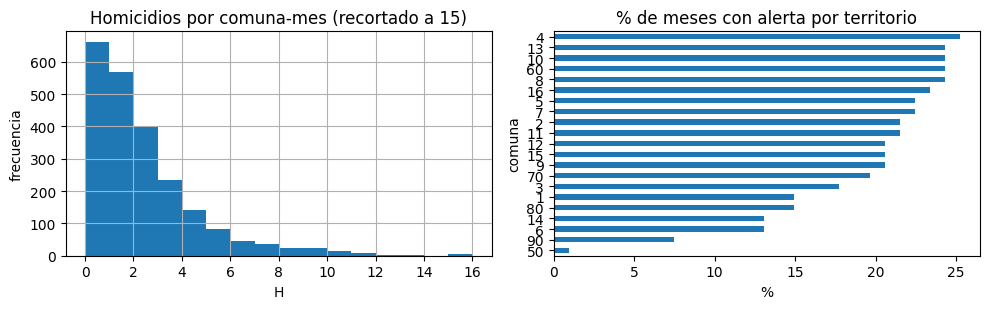

In [6]:
# ═══ 3. PARTICIÓN CRONOLÓGICA Y EDA ═════════════════════════════════
# Es una serie de tiempo: entreno con el pasado y evalúo con el futuro (nunca mezclo al azar).
def split(f):
    if "2015-01-01" <= str(f.date()) <= "2020-12-01": return "train"   # entrenamiento: aquí la red aprende
    if "2021-01-01" <= str(f.date()) <= "2022-12-01": return "val"     # validación: aquí ajusto decisiones (umbral, tamaño de red)
    if "2023-01-01" <= str(f.date()) <= "2023-11-01": return "test"    # prueba: se usa UNA sola vez al final
    return "fuera"
data["split"] = data["fecha"].map(split)
data = data[data["split"] != "fuera"].reset_index(drop=True)

# Tabla con cuántas observaciones y cuántas alertas hay en cada parte (la prevalencia es el % de alertas)
res = data.groupby("split")["y"].agg(observaciones="size", alertas="sum")
res["prevalencia_%"] = (100 * res["alertas"] / res["observaciones"]).round(1)
display(res.loc[["train", "val", "test"]])

# Dos gráficas del EDA: cómo se reparten los conteos y qué % de meses con alerta tiene cada territorio
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
data["H"].clip(upper=15).hist(bins=range(0, 17), ax=ax[0]); ax[0].set_title("Homicidios por comuna-mes (recortado a 15)")
ax[0].set_xlabel("H"); ax[0].set_ylabel("frecuencia")
(data.groupby("comuna")["y"].mean() * 100).sort_values().plot.barh(ax=ax[1]); ax[1].set_title("% de meses con alerta por territorio")
ax[1].set_xlabel("%"); plt.tight_layout(); plt.show()


## 3b. Anexo A — parte MEData (diez claves reales)
Elige 10 claves `(comuna, mes)` reales **sin repetir imagen** y calcula la imagen que corresponde por la regla `m−2`. Lo que sigue pendiente (descargar el VNP46A3 con su token Earthdata y leer la fecha de producción del nombre) se hace fuera de este cuaderno.

In [7]:
# ═══ 3b. ANEXO A (parte MEData): diez claves reales ═════════════════
# Elijo 10 parejas (territorio, mes) reales, con meses distintos, y calculo qué imagen de NASA les tocaría (la de 2 meses antes).
rng_a = np.random.RandomState(SEED)     # generador de azar con semilla, para que la elección sea siempre la misma
# Me quedo solo con filas que EXISTEN en el archivo original (no con los ceros que rellené yo)
cand = data.merge(conteos[["comuna", "fecha"]], on=["comuna", "fecha"], how="inner")
cand = cand[(cand["fecha"] >= "2021-03-01") & (cand["fecha"] <= FIN)].copy()
meses_unicos = rng_a.choice(sorted(cand["fecha"].unique()), size=10, replace=False)   # 10 meses distintos
filas = []
for k, f in enumerate(sorted(meses_unicos), 1):
    g = cand[cand["fecha"] == f]
    r = g.iloc[rng_a.randint(len(g))]                                   # un territorio al azar de ese mes
    f_img = (pd.Timestamp(f) - pd.DateOffset(months=2))                 # imagen permitida: la de m-2 (para no usar información demasiado reciente)
    doy = f_img.dayofyear                                               # día del año del primer día del mes: así se nombra el compuesto mensual
    filas.append({"N.º": k, "clave (comuna, año-mes)": f"({r['comuna']}, {pd.Timestamp(f):%Y-%m})",
                  "H (Conducta=Homicidio)": int(r["H"]),
                  "imagen usada (m-2)": f"{f_img:%Y-%m}",
                  "prefijo esperado (SIN verificar)": f"VNP46A3.A{f_img.year}{doy:03d}.h10v08.002."})
tabla_A = pd.DataFrame(filas); display(tabla_A)
tabla_A.to_csv("results/anexoA_parte_MEData.csv", index=False)
print("Falta: nombre exacto del .h5 y fecha de producción (últimos 13 dígitos del nombre) tras descargar cada archivo.")


,N.º,"clave (comuna, año-mes)",H (Conducta=Homicidio),imagen usada (m-2),prefijo esperado (SIN verificar)
0,1,"(6, 2021-03)",1,2021-01,VNP46A3.A2021001.h10v08.002.
1,2,"(70, 2021-11)",1,2021-09,VNP46A3.A2021244.h10v08.002.
2,3,"(7, 2021-12)",4,2021-10,VNP46A3.A2021274.h10v08.002.
3,4,"(9, 2022-03)",2,2022-01,VNP46A3.A2022001.h10v08.002.
4,5,"(13, 2022-06)",5,2022-04,VNP46A3.A2022091.h10v08.002.
5,6,"(8, 2022-08)",1,2022-06,VNP46A3.A2022152.h10v08.002.
6,7,"(2, 2022-10)",2,2022-08,VNP46A3.A2022213.h10v08.002.
7,8,"(15, 2022-12)",1,2022-10,VNP46A3.A2022274.h10v08.002.
8,9,"(90, 2023-05)",1,2023-03,VNP46A3.A2023060.h10v08.002.
9,10,"(6, 2023-10)",2,2023-08,VNP46A3.A2023213.h10v08.002.


Falta: nombre exacto del .h5 y fecha de producción (últimos 13 dígitos del nombre) tras descargar cada archivo.


## 4. Líneas base (se calculan en validación/prueba y se conservan para la Fase 2)

In [8]:
# ═══ 4. LÍNEAS BASE (referencias contra las que comparo el MLP) ═════
def metricas(y, pred, score=None):
    # y = alertas reales · pred = alertas predichas (0/1) · score = puntaje continuo (para el PR-AUC)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)   # precisión, recall y F1 de cada clase
    return {"exactitud": float((y == pred).mean()),            # % de meses bien clasificados (engaña cuando hay desbalance)
            "precision_1": p[1], "recall_1": r[1], "f1_1": f1[1],   # clase 1 = alerta: de las alertas que emití, ¿cuántas eran reales? / de las reales, ¿cuántas detecté?
            "precision_0": p[0], "recall_0": r[0], "f1_0": f1[0],   # clase 0 = sin alerta
            "pr_auc": float(average_precision_score(y, score)) if score is not None and y.sum() > 0 else np.nan}   # PR-AUC: calidad del ranking de riesgo

# Separo las tres partes que armé arriba
tr, va, te = (data[data.split == s] for s in ["train", "val", "test"])
ytr, yva, yte = tr["y"].values, va["y"].values, te["y"].values

# Línea base 1: clase mayoritaria = decir siempre la clase más frecuente del entrenamiento (aquí «sin alerta»)
clase_may = int(ytr.mean() > 0.5)
base1 = metricas(yte, np.full_like(yte, clase_may))

# Línea base 2: regla simple del conteo previo = alertar si el mes anterior estuvo por encima del promedio de 12 meses
# El umbral de la regla lo elijo en VALIDACIÓN (el que maximiza el F1), no en prueba.
score_regla = lambda d: (d["lag1"] - d["media12"]).values
sv = score_regla(va)
umbrales = np.unique(np.quantile(sv, np.linspace(0.05, 0.95, 60)))
mejor_u = max(umbrales, key=lambda u: fbeta_score(yva, (sv > u).astype(int), beta=1, zero_division=0))
base2 = metricas(yte, (score_regla(te) > mejor_u).astype(int), score_regla(te))
print("Clase mayoritaria =", clase_may, "| umbral de la regla (validación):", round(float(mejor_u), 3))
display(pd.DataFrame({"mayoritaria": base1, "regla_conteo_previo": base2}).T.round(3))


Clase mayoritaria = 0 | umbral de la regla (validación): -1.542


,exactitud,precision_1,recall_1,f1_1,precision_0,recall_0,f1_0,pr_auc
mayoritaria,0.810,0.000,0.000,0.000,0.810,1.000,0.895,NaN
regla_conteo_previo,0.251,0.197,0.955,0.327,0.889,0.086,0.156,0.168


## 5. Preprocesamiento (ajustado solo con entrenamiento) y MLP

**Por qué ReLU en las capas ocultas.** Si entre capa y capa no hubiera una función no lineal, apilar capas equivaldría a una sola transformación lineal y la red no podría aprender nada más complejo que una regresión. ReLU (`max(0, z)`) aporta esa no linealidad con un cálculo muy simple.

**Por qué la salida es un logit.** La última capa entrega un número sin acotar. `BCEWithLogitsLoss` le aplica la sigmoide por dentro (más estable numéricamente) y yo la aplico a mano con `torch.sigmoid` solo al evaluar. Así evito la «doble sigmoide».

**Capacidad de la red.** La justifico con una comparación medida: en la sección 6 pruebo redes de 16-8 y de 64-32 neuronas.


In [9]:
# ═══ 5. PREPROCESAMIENTO (ajustado SOLO con entrenamiento) ══════════
# El territorio lo convierto en 21 columnas de 0/1 (una por territorio), porque la red necesita números, no códigos.
dummies = pd.get_dummies(data["comuna"], prefix="c", dtype=float)
# El escalador aprende la media y la desviación de cada variable SOLO con el entrenamiento.
# Si lo ajustara con todos los datos, la prueba influiría en el preprocesamiento (fuga de datos).
sc = StandardScaler().fit(tr[FEATURES_NUM])

def matriz(d):
    num = sc.transform(d[FEATURES_NUM])                                # 12 variables numéricas, escaladas
    return np.hstack([num, dummies.loc[d.index].values]).astype("float32")   # + 21 columnas de territorio = 33 entradas

Xtr, Xva, Xte = matriz(tr), matriz(va), matriz(te)
print("Formas:", Xtr.shape, Xva.shape, Xte.shape)    # (observaciones, 33 entradas) en cada parte


Formas: (1512, 33) (504, 33) (231, 33)


In [10]:
# ═══ 5b. EL MLP Y EL BUCLE DE ENTRENAMIENTO ═════════════════════════
# [TORCH] Paso los datos de NumPy a «tensores», que es el formato que entiende PyTorch.
Xtr_t, Xva_t, Xte_t = (torch.as_tensor(x) for x in (Xtr, Xva, Xte))
ytr_t, yva_t, yte_t = (torch.as_tensor(y).float().view(-1, 1) for y in (ytr, yva, yte))   # etiquetas como decimales, en columna (N, 1)

class MLP(nn.Module):
    # Red de dos capas ocultas con ReLU. La salida es un LOGIT (número sin acotar): no pongo sigmoide aquí
    # porque BCEWithLogitsLoss ya la incluye al entrenar y yo la aplico a mano al evaluar (evito la «doble sigmoide»).
    def __init__(self, n_feat, h1=16, h2=8, p_dropout=0.0):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(n_feat, h1), nn.ReLU(), nn.Dropout(p_dropout),   # capa oculta 1: 33 entradas -> 16 neuronas
            nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(p_dropout),       # capa oculta 2: 16 -> 8 neuronas
            nn.Linear(h2, 1))                                          # salida: 8 -> 1 logit
    def forward(self, x):
        return self.red(x)                                             # «forward» = pasar los datos por la red

def entrenar(Xa, ya, Xv, yv, h1=16, h2=8, p=0.0, epocas=100, lr=1e-3, batch=64,
             paciencia=None, restaurar=True, semilla=SEED):
    # Xa/ya = datos de entrenamiento · Xv/yv = datos de validación · h1,h2 = neuronas · p = Dropout
    # lr = tasa de aprendizaje (tamaño del paso) · batch = filas por lote · paciencia = épocas sin mejorar antes de parar
    torch.manual_seed(semilla)
    modelo = MLP(Xa.shape[1], h1, h2, p)
    criterio = nn.BCEWithLogitsLoss()                         # pérdida: entropía cruzada binaria sobre logits
    optim = torch.optim.Adam(modelo.parameters(), lr=lr)      # Adam: el optimizador que va ajustando los pesos
    gen = torch.Generator().manual_seed(semilla)              # azar fijo para barajar los lotes
    hist = {"train": [], "val": []}                           # aquí guardo la pérdida de cada época (para las curvas)
    mejor, mejor_ep, mejor_estado, sin_mejora = float("inf"), 0, None, 0
    for ep in range(1, epocas + 1):                           # una época = una pasada completa por el entrenamiento
        modelo.train()                                        # modo entrenamiento (Dropout activo)
        perm = torch.randperm(len(Xa), generator=gen)         # barajo las filas
        for i in range(0, len(Xa), batch):                    # recorro el entrenamiento en lotes de 64
            ix = perm[i:i + batch]
            logits = modelo(Xa[ix])            # 1 · forward: la red calcula su predicción (logit)
            perdida = criterio(logits, ya[ix]) # 2 · pérdida: qué tan lejos quedó de la etiqueta real
            optim.zero_grad()                  # 3 · borro los gradientes del paso anterior (si no, se acumulan)
            perdida.backward()                 # 4 · retropropagación: calcula cuánto contribuyó cada peso al error
            optim.step()                       # 5 · actualizo los pesos para reducir el error
        modelo.eval()                                         # modo evaluación (Dropout apagado)
        with torch.no_grad():                                 # no necesito gradientes para medir
            lt = criterio(modelo(Xa), ya).item()              # pérdida en entrenamiento
            lv = criterio(modelo(Xv), yv).item()              # pérdida en validación
        hist["train"].append(lt); hist["val"].append(lv)
        if lv < mejor:                                        # PARADA TEMPRANA: si la validación mejoró, guardo una copia de los pesos
            mejor, mejor_ep, sin_mejora = lv, ep, 0
            mejor_estado = copy.deepcopy(modelo.state_dict())
        else:
            sin_mejora += 1
            if paciencia is not None and sin_mejora >= paciencia:   # si pasan 15 épocas sin mejorar, detengo el entrenamiento
                break
    if restaurar:
        modelo.load_state_dict(mejor_estado)                  # me quedo con la versión de la mejor época, no con la última
    return modelo, hist, mejor_ep, mejor

def probs(modelo, X):
    modelo.eval()
    with torch.no_grad():
        return torch.sigmoid(modelo(X)).numpy().ravel()   # sigmoide: convierte el logit en probabilidad (0 a 1). Solo se aplica aquí
print("Modelo y bucle definidos.")


Modelo y bucle definidos.


## 6. Sobreajuste inducido y corregido
Se reduce el entrenamiento a unos cientos de filas y se agranda la red para **provocar** sobreajuste; luego se corrige con Dropout o con una red menor. Escribe debajo de la gráfica la época del mínimo de validación de cada corrida y qué se observa.

,corrida,época del mínimo de validación,pérdida mínima de validación,brecha final (val - train)
0,"grande, sin Dropout",5,0.4888,2.6479
1,grande + Dropout 0.5,6,0.4886,1.6498
2,pequeña (16-8),28,0.4961,1.0916


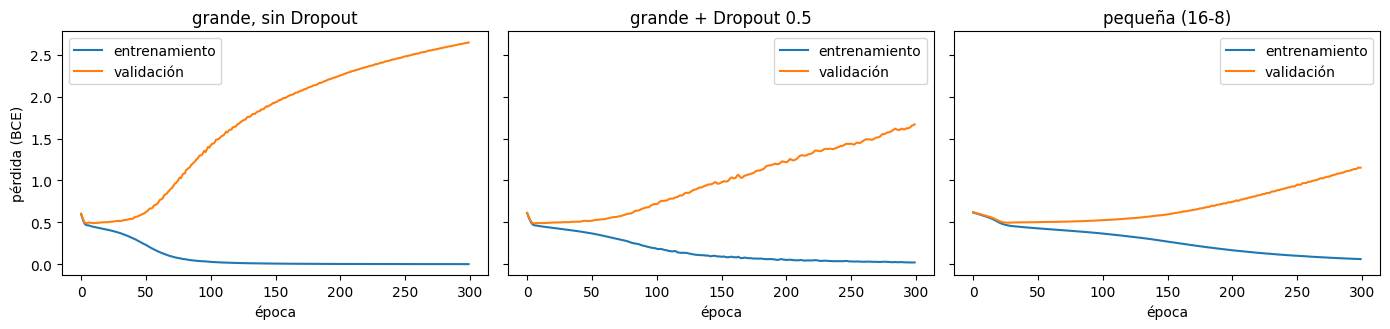

In [11]:
# ═══ 6. SOBREAJUSTE INDUCIDO Y CORREGIDO ════════════════════════════
# [TORCH] Quiero VER el sobreajuste: entreno con solo 300 filas, redes grandes y 300 épocas, sin parar ni restaurar.
rng = np.random.RandomState(SEED)
sub = rng.choice(len(Xtr_t), size=min(300, len(Xtr_t)), replace=False)   # 300 filas al azar del entrenamiento
Xs, ys = Xtr_t[sub], ytr_t[sub]

# Tres corridas para comparar: una que sobreajuste y dos formas de corregirlo (Dropout o red más pequeña)
corridas = {
    "grande, sin Dropout":  dict(h1=128, h2=64, p=0.0),   # mucha capacidad y sin freno: debería memorizar
    "grande + Dropout 0.5": dict(h1=128, h2=64, p=0.5),   # apago el 50 % de las neuronas en cada paso
    "pequeña (16-8)":       dict(h1=16, h2=8, p=0.0),     # menos capacidad para memorizar
}
resumen, hists = [], {}
for nombre, cfg in corridas.items():
    m, h, ep, mv = entrenar(Xs, ys, Xva_t, yva_t, epocas=300, restaurar=False, **cfg)
    hists[nombre] = h
    resumen.append({"corrida": nombre, "época del mínimo de validación": ep,       # época donde la validación fue mejor
                    "pérdida mínima de validación": round(mv, 4),
                    "brecha final (val - train)": round(h["val"][-1] - h["train"][-1], 4)})   # cuánto más alta es la pérdida de validación que la de entrenamiento
display(pd.DataFrame(resumen))

# Curvas: si la de entrenamiento baja y la de validación sube, hay sobreajuste
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
for a, (nombre, h) in zip(ax, hists.items()):
    a.plot(h["train"], label="entrenamiento"); a.plot(h["val"], label="validación")
    a.set_title(nombre); a.set_xlabel("época"); a.legend()
ax[0].set_ylabel("pérdida (BCE)"); plt.tight_layout(); plt.show()


**Interpretación de la sección 6** (resultados de la tabla y las curvas de arriba):

- **Grande, sin Dropout:** la pérdida de validación toca su mínimo en la **época 5** (0,4888) y después sube mientras la de entrenamiento cae casi a 0. Esa es la señal de sobreajuste: la red memoriza las 300 filas. La brecha final (validación − entrenamiento) es de 2,6479.
- **Grande + Dropout 0,5:** el mínimo llega en la **época 6** (0,4886) y la brecha baja a 1,6498. El Dropout atenúa el sobreajuste, pero no lo elimina.
- **Pequeña (16-8):** el mínimo llega en la **época 28** (0,4961) y la brecha es de 1,0916. Una red menor también reduce el sobreajuste, sin eliminarlo.
- **Conclusión:** lo que realmente evita el daño es la **parada temprana**: quedarme con los pesos de la época del mínimo de validación.


### Modelo final: comparación de tamaños con el entrenamiento completo y parada temprana

Con las 1.512 filas de entrenamiento, los tres candidatos terminan casi empatados (pérdida de validación entre 0,4748 y 0,4787; diferencia de 0,002 a 0,004, sin significado práctico). El elegido es el de menor pérdida de validación: **16-8 sin Dropout, mejor época 70**. La referencia es la pérdida de predecir siempre la prevalencia (≈ 0,487, ver sección 10): el modelo mejora apenas ≈ 2,5 %.


,modelo,mejor época,pérdida val mínima,brecha (val-train) final
0,"16-8, Dropout 0.2",28,0.4787,0.0268
1,"16-8, sin Dropout",70,0.4748,0.0594
2,"64-32, Dropout 0.2",29,0.4767,0.0637


Modelo elegido por mínimo de validación: 16-8, sin Dropout


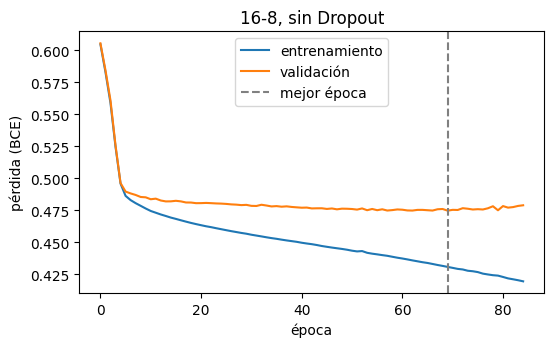

In [12]:
# ═══ 6b. MODELO FINAL: comparo tamaños con el entrenamiento COMPLETO ═
# [TORCH] Ahora sí uso las 1.512 filas de entrenamiento, con parada temprana (paciencia 15) y restaurando la mejor época.
cands = {"16-8, Dropout 0.2": dict(h1=16, h2=8, p=0.2),
         "16-8, sin Dropout": dict(h1=16, h2=8, p=0.0),
         "64-32, Dropout 0.2": dict(h1=64, h2=32, p=0.2)}
modelos, filas, curvas = {}, [], {}
for nombre, cfg in cands.items():
    m, h, ep, mv = entrenar(Xtr_t, ytr_t, Xva_t, yva_t, epocas=100, paciencia=15, restaurar=True, **cfg)
    modelos[nombre], curvas[nombre] = m, h
    filas.append({"modelo": nombre, "mejor época": ep, "pérdida val mínima": round(mv, 4),
                  "brecha (val-train) final": round(h["val"][-1] - h["train"][-1], 4)})
tabla = pd.DataFrame(filas); display(tabla)
# Elijo el de menor pérdida de validación (nunca por la prueba)
elegido = tabla.sort_values("pérdida val mínima").iloc[0]["modelo"]
modelo_final = modelos[elegido]
print("Modelo elegido por mínimo de validación:", elegido)

# Curva del modelo elegido, con una línea punteada en la mejor época
h = curvas[elegido]
plt.figure(figsize=(6, 3.4)); plt.plot(h["train"], label="entrenamiento"); plt.plot(h["val"], label="validación")
plt.axvline(int(tabla.set_index("modelo").loc[elegido, "mejor época"]) - 1, ls="--", c="gray", label="mejor época")
plt.xlabel("época"); plt.ylabel("pérdida (BCE)"); plt.title(elegido); plt.legend(); plt.show()
torch.save(modelo_final.state_dict(), "results/mlp_final.pt")   # guardo los pesos del modelo final


## 7. Evaluación final (la prueba se usa UNA sola vez)

Umbral elegido en validación (beta=1.0): 0.23


,exactitud,precision_1,recall_1,f1_1,precision_0,recall_0,f1_0,pr_auc
mayoritaria,0.810,0.000,0.000,0.000,0.810,1.000,0.895,NaN
regla_conteo_previo,0.251,0.197,0.955,0.327,0.889,0.086,0.156,0.168
MLP,0.550,0.174,0.364,0.235,0.799,0.594,0.681,0.188


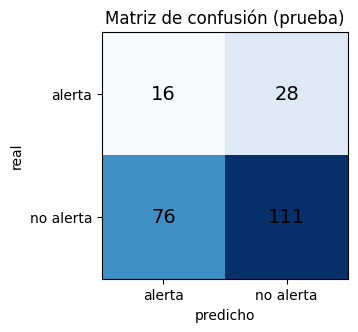

VP=16  FN=28  FP=76  VN=111


In [13]:
# ═══ 7. EVALUACIÓN FINAL (la prueba se usa UNA sola vez) ════════════
# [TORCH] El umbral de decisión se elige en VALIDACIÓN. BETA > 1 prioriza no omitir alertas (falsos negativos); con 1.0 doy igual peso a precisión y recall.
BETA = 1.0
pv = probs(modelo_final, Xva_t)                  # probabilidades de alerta en validación
grid = np.linspace(0.05, 0.95, 91)               # umbrales candidatos: 0,05; 0,06; … ; 0,95
umbral = max(grid, key=lambda u: fbeta_score(yva, (pv >= u).astype(int), beta=BETA, zero_division=0))   # el que da mejor F1 en validación
print(f"Umbral elegido en validación (beta={BETA}): {umbral:.2f}")

pt = probs(modelo_final, Xte_t)                  # probabilidades en la PRUEBA (primera y única vez que se usa)
pred = (pt >= umbral).astype(int)                # alerta = 1 si la probabilidad alcanza el umbral
mlp = metricas(yte, pred, pt)
comparacion = pd.DataFrame({"mayoritaria": base1, "regla_conteo_previo": base2, "MLP": mlp}).T.round(3)   # tabla comparativa final
display(comparacion)

# Matriz de confusión: filas = lo real, columnas = lo predicho
cm = confusion_matrix(yte, pred, labels=[1, 0])   # orden (alerta, no alerta) en filas y columnas
fig, ax = plt.subplots(figsize=(3.6, 3.2)); ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha="center", va="center", fontsize=14)
ax.set_xticks([0, 1]); ax.set_xticklabels(["alerta", "no alerta"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["alerta", "no alerta"])
ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title("Matriz de confusión (prueba)"); plt.show()
print(f"VP={cm[0,0]}  FN={cm[0,1]}  FP={cm[1,0]}  VN={cm[1,1]}")   # VP acierto en alerta · FN alerta no avisada · FP falsa alarma · VN acierto en no alerta
comparacion.to_csv("results/metricas_prueba.csv")


## 8. Errores por territorio (falsos negativos)

In [14]:
# ═══ 8. ERRORES POR TERRITORIO ══════════════════════════════════════
# [TORCH] Quiero saber si el modelo falla más en unos territorios que en otros (auditoría de equidad).
aud = te[["comuna", "fecha", "y"]].copy(); aud["pred"] = pred   # junto lo real y lo predicho de la prueba
def por_territorio(g):
    reales = int(g["y"].sum())                                              # alertas reales del territorio
    fn = int(((g["y"] == 1) & (g["pred"] == 0)).sum())                      # falsos negativos: había alerta y no avisé
    fp = int(((g["y"] == 0) & (g["pred"] == 1)).sum())                      # falsos positivos: avisé y no había alerta
    return pd.Series({"meses": len(g), "alertas reales": reales, "falsos negativos": fn, "falsos positivos": fp,
                      "recall": round(1 - fn / reales, 2) if reales > 0 else np.nan})   # recall = % de alertas reales que sí detecté
tabla_terr = aud.groupby("comuna").apply(por_territorio)
display(tabla_terr.sort_values("alertas reales", ascending=False))
print("Con pocas alertas reales por territorio, el recall por territorio es muy incierto: se reporta como indicio, no como ranking.")


/tmp/ipykernel_929/3511920022.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tabla_terr = aud.groupby("comuna").apply(por_territorio)


,meses,alertas reales,falsos negativos,falsos positivos,recall
comuna,,,,,
8,11.0,5.0,2.0,2.0,0.60
3,11.0,4.0,4.0,0.0,0.00
6,11.0,4.0,4.0,0.0,0.00
5,11.0,4.0,2.0,6.0,0.50
10,11.0,4.0,0.0,5.0,1.00
15,11.0,3.0,3.0,2.0,0.00
11,11.0,3.0,1.0,4.0,0.67
80,11.0,2.0,2.0,1.0,0.00
70,11.0,2.0,2.0,5.0,0.00


Con pocas alertas reales por territorio, el recall por territorio es muy incierto: se reporta como indicio, no como ranking.


## 8b. Ajuste v2: mismo problema, mejor información y una evaluación más honesta

**Objetivo.** Comprobar si el MLP mejora cuando se corrigen tres debilidades de la v1, sin cambiar el problema, la etiqueta ni las particiones, y medir con más cuidado si la mejora es real o es ruido.

| Cambio | Por qué se hace |
| --- | --- |
| Se agrega `p75_12` (el percentil 75 de los 12 meses anteriores) como entrada | La etiqueta compara `H` con ese valor; la v1 no se lo daba a la red. Se calcula solo con meses anteriores (sin fuga). |
| Se quitan `suma3`, `suma6`, `suma12` y `delta` | Son combinaciones exactas de otras entradas (suma = media × ventana; delta = lag1 − lag2): no aportan información y solo agregan ruido. Quedan 9 variables numéricas + 21 de territorio = 30 entradas. |
| `weight_decay=1e-4`, paciencia 20 y mejora mínima 1e-4 | Frena pesos grandes y evita que la parada temprana se active por diferencias ínfimas. |
| Umbral por **presupuesto de alertas** (el 20 % de meses con mayor probabilidad en validación) | El umbral que maximiza F1 en validación es inestable con pocas alertas; un presupuesto fijo es más fácil de explicar y de reproducir. |
| 5 semillas (7, 21, 42, 73, 101) en vez de una | Medir cuánto varía el resultado entre ejecuciones. |
| Comparación con el azar (prueba de permutación) y con líneas base de **igual número de alertas** | La regla del conteo previo de la v1 alertaba en el 92 % de los meses, así que su recall alto no era una comparación justa. |

**Declaración sobre la prueba.** La v1 ya usó la prueba una vez. Esta sección la usa por segunda vez, con un diseño fijado antes de ver su resultado; ninguna decisión (rasgos, umbral, semilla representativa) se tomó mirando la prueba. La semilla representativa es la 42 por ser la de todo el cuaderno, no por su desempeño.

In [15]:
# ═══ 8b-1. AJUSTE v2: ENTRENAMIENTO CON 5 SEMILLAS Y COMPARACIÓN v1 / v2 ═══════════
# Objetivo: medir, con la misma partición, si los rasgos y el entrenamiento nuevos mejoran la v1 y cuánto varía el resultado entre semillas.
from sklearn.metrics import average_precision_score
FEATURES_V2 = ["lag1","lag2","lag3","media3","media6","media12","p75_12","mes_sin","mes_cos"]   # 9 numéricas (con p75_12, sin redundantes)
SEMILLAS = [7, 21, 42, 73, 101]     # cinco semillas para ver la variación entre ejecuciones
PRESUPUESTO = 0.20                  # umbral por presupuesto: alerta el 20 % de los meses con mayor probabilidad (corte fijado en validación)

def entrenar_v2(Xa, ya, Xv, yv, h1=16, h2=8, p=0.0, epocas=200, lr=1e-3, batch=64,
                paciencia=20, min_delta=1e-4, wd=1e-4, semilla=SEED):
    # Igual que «entrenar» de la sección 5b, con dos añadidos: weight_decay en Adam (penaliza pesos grandes)
    # y min_delta (una mejora de la validación solo cuenta si supera ese margen). Siempre restaura la mejor época.
    torch.manual_seed(semilla)
    modelo = MLP(Xa.shape[1], h1, h2, p)
    criterio = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=wd)
    gen = torch.Generator().manual_seed(semilla)
    hist = {"train": [], "val": []}
    mejor, mejor_ep, mejor_estado, sin_mejora = float("inf"), 0, None, 0
    for ep in range(1, epocas + 1):
        modelo.train()
        perm = torch.randperm(len(Xa), generator=gen)
        for i in range(0, len(Xa), batch):
            ix = perm[i:i + batch]
            perdida = criterio(modelo(Xa[ix]), ya[ix])      # forward + pérdida
            optim.zero_grad(); perdida.backward(); optim.step()   # gradientes a cero, retropropagación y actualización
        modelo.eval()
        with torch.no_grad():
            lt = criterio(modelo(Xa), ya).item(); lv = criterio(modelo(Xv), yv).item()
        hist["train"].append(lt); hist["val"].append(lv)
        if lv < mejor - min_delta:
            mejor, mejor_ep, sin_mejora = lv, ep, 0
            mejor_estado = copy.deepcopy(modelo.state_dict())
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejor_estado)
    return modelo, hist, mejor_ep, mejor

def correr_config(feats, **kw):
    sc_ = StandardScaler().fit(tr[feats])    # el escalador se ajusta SOLO con entrenamiento
    mk = lambda d: torch.as_tensor(np.hstack([sc_.transform(d[feats]), dummies.loc[d.index].values]).astype("float32"))
    Xa, Xv, Xt = mk(tr), mk(va), mk(te)
    filas, PV, PT = [], {}, {}
    for s in SEMILLAS:
        m, h, ep, mv = entrenar_v2(Xa, ytr_t, Xv, yva_t, semilla=s, **kw)
        pv, pt = probs(m, Xv), probs(m, Xt)
        u = float(np.quantile(pv, 1 - PRESUPUESTO))              # umbral = percentil 80 de las probabilidades de VALIDACIÓN
        mv_ = metricas(yva, (pv >= u).astype(int), pv)
        mt_ = metricas(yte, (pt >= u).astype(int), pt)
        filas.append({"semilla": s, "mejor época": ep, "pérdida val": mv, "AP val": mv_["pr_auc"], "AP prueba": mt_["pr_auc"],
                      "F1 val": mv_["f1_1"], "F1 prueba": mt_["f1_1"], "precisión prueba": mt_["precision_1"], "recall prueba": mt_["recall_1"]})
        PV[s], PT[s] = pv, pt
    return pd.DataFrame(filas), PV, PT

CONFIGS = {
    "v1 (rasgos y entrenamiento originales)":  (FEATURES_NUM, dict(epocas=100, paciencia=15, min_delta=0.0, wd=0.0)),
    "v2a (solo rasgos nuevos)":                (FEATURES_V2,  dict(epocas=100, paciencia=15, min_delta=0.0, wd=0.0)),
    "v2 (rasgos nuevos + weight_decay + paciencia 20)": (FEATURES_V2, dict(epocas=200, paciencia=20, min_delta=1e-4, wd=1e-4)),
}
res_cfg, probs_cfg, resumen_cfg = {}, {}, []
for nombre, (feats, kw) in CONFIGS.items():
    df_s, PV_, PT_ = correr_config(feats, **kw)
    res_cfg[nombre], probs_cfg[nombre] = df_s, (PV_, PT_)
    resumen_cfg.append({"configuración": nombre,
                        "AP val (media ± sd)": f"{df_s['AP val'].mean():.3f} ± {df_s['AP val'].std(ddof=1):.3f}",
                        "AP prueba (media ± sd)": f"{df_s['AP prueba'].mean():.3f} ± {df_s['AP prueba'].std(ddof=1):.3f}",
                        "pérdida val (media)": round(df_s["pérdida val"].mean(), 4),
                        "F1 prueba (media)": round(df_s["F1 prueba"].mean(), 3)})
print(f"Prevalencia de alertas: validación {yva.mean():.3f} · prueba {yte.mean():.3f} (un clasificador sin señal tiene PR-AUC cercano a ese valor)")
display(pd.DataFrame(resumen_cfg))
print("\nDetalle por semilla del modelo v2:"); display(res_cfg[list(CONFIGS)[-1]].round(4))
pd.concat({k: v for k, v in res_cfg.items()}, names=["configuración"]).to_csv("results/ajuste_v2_por_semilla.csv")


Prevalencia de alertas: validación 0.190 · prueba 0.190 (un clasificador sin señal tiene PR-AUC cercano a ese valor)


,configuración,AP val (media ± sd),AP prueba (media ± sd),pérdida val (media),F1 prueba (media)
0,v1 (rasgos y entrenamiento originales),0.251 ± 0.017,0.183 ± 0.011,0.4781,0.121
1,v2a (solo rasgos nuevos),0.280 ± 0.010,0.214 ± 0.037,0.4725,0.181
2,v2 (rasgos nuevos + weight_decay + paciencia 20),0.276 ± 0.016,0.208 ± 0.034,0.4726,0.160



Detalle por semilla del modelo v2:


,semilla,mejor época,pérdida val,AP val,AP prueba,F1 val,F1 prueba,precisión prueba,recall prueba
0,7,43,0.4751,0.2673,0.1908,0.3452,0.1728,0.1892,0.1591
1,21,33,0.4734,0.2925,0.1939,0.3350,0.1395,0.1429,0.1364
2,42,48,0.4718,0.2740,0.1803,0.2944,0.0741,0.0811,0.0682
3,73,55,0.4691,0.2903,0.2665,0.3249,0.2051,0.2353,0.1818
4,101,38,0.4738,0.2551,0.2088,0.2741,0.2093,0.2143,0.2045


In [16]:
# ═══ 8b-2. ¿SUPERA AL AZAR? PRUEBA DE PERMUTACIÓN E INTERVALO (BOOTSTRAP) ═════════
# Objetivo: saber si el PR-AUC observado se distingue de lo que daría un puntaje sin relación con la etiqueta.
# Prueba de permutación: barajo las etiquetas muchas veces y cuento cuántas veces el azar iguala o supera el PR-AUC observado (valor p).
V2 = list(CONFIGS)[-1]
PV_v2, PT_v2 = probs_cfg[V2]
rng_p = np.random.RandomState(SEED)
def p_azar(y, score, n=2000):
    obs = average_precision_score(y, score)
    nulo = np.array([average_precision_score(rng_p.permutation(y), score) for _ in range(n)])
    return obs, float((nulo >= obs).mean())
def ic_boot(y, score, n=2000):
    ap = []
    for _ in range(n):
        i = rng_p.randint(0, len(y), len(y))
        if y[i].sum() > 0:
            ap.append(average_precision_score(y[i], score[i]))
    return np.percentile(ap, [2.5, 97.5])

ens_v = np.mean([PV_v2[s] for s in SEMILLAS], axis=0)    # promedio de las 5 semillas (referencia)
ens_t = np.mean([PT_v2[s] for s in SEMILLAS], axis=0)
filas = []
for nombre, pv_, pt_ in [("v2, semilla 42", PV_v2[42], PT_v2[42]), ("v2, promedio de 5 semillas", ens_v, ens_t)]:
    for parte, y, sc_ in [("validación", yva, pv_), ("prueba", yte, pt_)]:
        obs, p = p_azar(y, sc_); lo, hi = ic_boot(y, sc_)
        filas.append({"modelo": nombre, "conjunto": parte, "PR-AUC": round(obs, 3), "IC 95 % (bootstrap)": f"{lo:.3f} – {hi:.3f}",
                      "prevalencia": round(y.mean(), 3), "valor p (permutación)": round(p, 4)})
tabla_azar = pd.DataFrame(filas); display(tabla_azar)
tabla_azar.to_csv("results/ajuste_v2_vs_azar.csv", index=False)
print("Lectura: un valor p pequeño (< 0,05) indica que el PR-AUC difiere de lo esperable por azar; si el intervalo incluye la prevalencia, no hay evidencia de señal.")
print("Limitación: los meses de un mismo territorio no son independientes, así que los intervalos reales son algo más anchos que estos.")


,modelo,conjunto,PR-AUC,IC 95 % (bootstrap),prevalencia,valor p (permutación)
0,"v2, semilla 42",validación,0.274,0.216 – 0.364,0.19,0.0020
1,"v2, semilla 42",prueba,0.180,0.133 – 0.260,0.19,0.8210
2,"v2, promedio de 5 semillas",validación,0.277,0.215 – 0.357,0.19,0.0040
3,"v2, promedio de 5 semillas",prueba,0.204,0.149 – 0.305,0.19,0.4895


Lectura: un valor p pequeño (< 0,05) indica que el PR-AUC difiere de lo esperable por azar; si el intervalo incluye la prevalencia, no hay evidencia de señal.
Limitación: los meses de un mismo territorio no son independientes, así que los intervalos reales son algo más anchos que estos.


,alertas emitidas,exactitud,precision_1,recall_1,f1_1,pr_auc
mayoritaria (nunca alerta),0,0.810,0.000,0.000,0.000,NaN
alertar siempre,231,0.190,0.190,1.000,0.320,NaN
"regla conteo previo, umbral F1 (v1)",213,0.251,0.197,0.955,0.327,0.168
"regla conteo previo, 20% de alertas",40,0.697,0.175,0.159,0.167,0.168
MLP v1 (umbral F1 en validación),92,0.550,0.174,0.364,0.235,0.188
"MLP v2, semilla 42, 20% de alertas",37,0.675,0.081,0.068,0.074,0.180


MLP v2 (semilla 42, umbral 0.269): VP=3  FN=41  FP=34  VN=153
Por azar, con 37 alertas se esperarían ≈ 7.0 aciertos; el MLP v2 acertó 3.


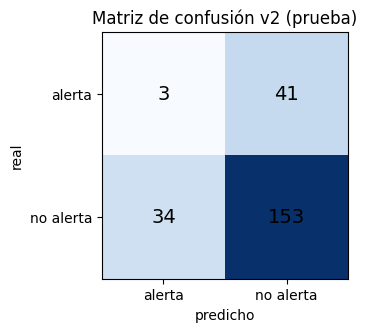


VEREDICTO AUTOMÁTICO (v2, promedio de 5 semillas)
· Validación: PR-AUC 0.277 frente a prevalencia 0.19 (p = 0.004) → se distingue del azar.
· Prueba: PR-AUC 0.204 frente a prevalencia 0.19 (p = 0.4895) → no se distingue del azar con 11 meses y 44 alertas.


In [17]:
# ═══ 8b-3. LÍNEAS BASE JUSTAS (IGUAL NÚMERO DE ALERTAS) Y MATRIZ DE CONFUSIÓN DE LA v2 ═════
# Objetivo: comparar el MLP con reglas que emiten el mismo número de alertas, para que el recall no dependa de alertar casi siempre.
def con_presupuesto(sv, st):
    u = np.quantile(sv, 1 - PRESUPUESTO)                 # corte fijado en VALIDACIÓN, aplicado a la prueba
    return (st >= u).astype(int)
sv_r, st_r = score_regla(va), score_regla(te)            # regla del conteo previo: lag1 − media12
pred_regla20 = con_presupuesto(sv_r, st_r)
u42 = float(np.quantile(PV_v2[42], 1 - PRESUPUESTO))
pred_v2 = (PT_v2[42] >= u42).astype(int)

comp = pd.DataFrame({
    "mayoritaria (nunca alerta)":                          base1,
    "alertar siempre":                                     metricas(yte, np.ones_like(yte)),
    "regla conteo previo, umbral F1 (v1)":                 base2,
    f"regla conteo previo, {PRESUPUESTO:.0%} de alertas":  metricas(yte, pred_regla20, st_r),
    "MLP v1 (umbral F1 en validación)":                    mlp,
    f"MLP v2, semilla 42, {PRESUPUESTO:.0%} de alertas":   metricas(yte, pred_v2, PT_v2[42]),
}).T.round(3)
comp["alertas emitidas"] = [0, len(yte), int(((score_regla(te) > mejor_u).astype(int)).sum()), int(pred_regla20.sum()), int(pred.sum()), int(pred_v2.sum())]
display(comp[["alertas emitidas", "exactitud", "precision_1", "recall_1", "f1_1", "pr_auc"]])
comp.to_csv("results/metricas_prueba_v2.csv")

cm2 = confusion_matrix(yte, pred_v2, labels=[1, 0])
print(f"MLP v2 (semilla 42, umbral {u42:.3f}): VP={cm2[0,0]}  FN={cm2[0,1]}  FP={cm2[1,0]}  VN={cm2[1,1]}")
print(f"Por azar, con {int(pred_v2.sum())} alertas se esperarían ≈ {pred_v2.sum() * yte.mean():.1f} aciertos; el MLP v2 acertó {cm2[0,0]}.")
fig, ax = plt.subplots(figsize=(3.6, 3.2)); ax.imshow(cm2, cmap="Blues")
for (i, j), v in np.ndenumerate(cm2): ax.text(j, i, v, ha="center", va="center", fontsize=14)
ax.set_xticks([0, 1]); ax.set_xticklabels(["alerta", "no alerta"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["alerta", "no alerta"])
ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title("Matriz de confusión v2 (prueba)"); plt.show()

# Veredicto calculado con los números de arriba (no escrito a mano)
fila_val = tabla_azar[(tabla_azar["modelo"] == "v2, promedio de 5 semillas") & (tabla_azar["conjunto"] == "validación")].iloc[0]
fila_te = tabla_azar[(tabla_azar["modelo"] == "v2, promedio de 5 semillas") & (tabla_azar["conjunto"] == "prueba")].iloc[0]
print("\nVEREDICTO AUTOMÁTICO (v2, promedio de 5 semillas)")
print(f"· Validación: PR-AUC {fila_val['PR-AUC']} frente a prevalencia {fila_val['prevalencia']} (p = {fila_val['valor p (permutación)']}) → " +
      ("se distingue del azar." if fila_val["valor p (permutación)"] < 0.05 else "no se distingue del azar."))
print(f"· Prueba: PR-AUC {fila_te['PR-AUC']} frente a prevalencia {fila_te['prevalencia']} (p = {fila_te['valor p (permutación)']}) → " +
      ("se distingue del azar." if fila_te["valor p (permutación)"] < 0.05 else "no se distingue del azar con 11 meses y 44 alertas."))


**Interpretación de la sección 8b** (salidas de la ejecución en Colab del 2026-11-08, 5 semillas, umbral del 20 % de alertas fijado en validación; si al reejecutar cambia algún decimal, actualizo estos números):

- **El ajuste mejora la validación de forma modesta.** El PR-AUC de validación pasa de 0,251 ± 0,017 (v1) a 0,280 ± 0,010 con solo los rasgos nuevos (v2a) y 0,276 ± 0,016 con `weight_decay` y paciencia 20 (v2). `weight_decay` y la paciencia no añaden nada: la mejora viene de los rasgos (el percentil 75 como entrada y quitar las entradas redundantes).
- **En validación sí hay señal:** PR-AUC 0,277 con el promedio de las semillas frente a una prevalencia de 0,190 (valor p de permutación 0,004). Es una señal débil, y algo optimista porque la parada temprana y la elección de época usan esa misma validación.
- **En prueba no hay evidencia de señal:** PR-AUC 0,204 con el promedio de las semillas (p ≈ 0,49; intervalo 95 % de 0,149 a 0,305, que incluye la prevalencia). Por semilla va de 0,180 a 0,267, así que el resultado depende mucho de la semilla; la media de la v2 (0,208 ± 0,034) y la de la v1 (0,183 ± 0,011) no se distinguen dada esa variación.
- **Semilla 42 (la fijada de antemano):** con el umbral 0,269 emitió 37 alertas y acertó 3 (VP=3, FN=41, FP=34, VN=153); por azar se esperaban ≈ 7. Su PR-AUC de prueba (0,180) tampoco se distingue del azar (p = 0,82). El umbral de validación dio menos del 20 % de alertas en prueba porque las probabilidades de la prueba salieron algo más bajas.
- **Frente a las líneas base justas:** la regla del conteo previo con 40 alertas obtiene precisión 0,175 y F1 0,167. El MLP v2 con la semilla 42 obtiene 0,081 y 0,074; con las cinco semillas su precisión promedio en prueba (0,173) es casi igual a la de la regla. No supera ni a la regla ni a «alertar siempre» (F1 0,320, que es alto solo porque alerta en todos los meses).
- **Conclusión:** el ajuste corrige debilidades reales de la v1 y mejora la validación, pero la prueba (11 meses, 44 alertas) no confirma una señal. Mantengo la recomendación de la sección 9: no usar este modelo para decidir ni priorizar territorios. Además, la prueba ya se usó dos veces (v1 y v2).


## 9. Reflexión ética y decisión

- **Costo de cada error (v1, umbral 0,23).** El MLP v1 emitió 92 alertas y 76 fueron falsas (82,6 %): *falso positivo* = estigma territorial y gasto de recursos en un territorio sin repunte. Además omitió 28 de 44 repuntes reales (63,6 %): *falso negativo* = un repunte sin aviso y sin prevención. Con la v2 (semilla 42, 20 % de alertas), 34 de 37 alertas fueron falsas (91,9 %) y 41 de 44 repuntes no se avisaron (93,2 %); la matriz está en la sección 8b.
- **Principio del *Marco ético para la IA en Colombia* (Guío Español et al., 2021): transparencia y explicación.** Lo aplico declarando que la v1 no superó al azar (PR-AUC 0,188 frente a una prevalencia de 19,0 %), que la v2 se hizo para corregir debilidades concretas y no para «mejorar la cifra», y que el veredicto de la sección 8b se calcula con una prueba de permutación; no publico rankings de peligrosidad por territorio.
- **Decisión recomendada al cliente:** mientras la prueba no muestre una señal distinguible del azar (veredicto de la sección 8b), **no usar este modelo para decidir ni para priorizar territorios.** Si se reutiliza el enfoque: verificación humana de toda alerta, reporte de falsos positivos por territorio y un periodo de prueba más largo. Cambiar `BETA` o el presupuesto de alertas solo tendría sentido cuando exista un modelo con señal demostrada.
- **Uso repetido de la prueba.** La prueba se evaluó dos veces (v1 y v2). La v2 se fijó antes de ver su resultado en prueba, pero esa repetición se declara porque reduce el valor de la prueba como evidencia independiente.
- **Brecha entre territorios** (sección 8): con 0 a 5 alertas reales por territorio, el recall por territorio es solo un indicio. Por ejemplo, el territorio 8 (5 alertas reales) detectó 3, y los territorios 3 y 6 (4 alertas reales cada uno) no detectaron ninguna.
- **Límites:** hechos registrados no son hechos ocurridos; los ceros rellenados no equivalen a ausencia real; la prueba es corta (11 meses, 44 alertas); cinco semillas pero una sola partición; y la radiancia nocturna todavía no se usa.


## Anexos del cuaderno
- **SHA-256 y fecha de descarga:** impresos en la sección 1 → los copio al anexo B1 de la propuesta.
- **Comprobación de réplicas de terceros en el código:** el comando está en el anexo B2 de `ANEXOS_FASE1.md` (se corre en una terminal, no se pega aquí para que no se autodetecte).
- **Descarga de NASA (VNP46A3):** en `02_anexoA_nasa_earthaccess.ipynb` (los diez SHA-256 están en el anexo B1).
- **Archivos que genera la v2:** `results/ajuste_v2_por_semilla.csv`, `results/ajuste_v2_vs_azar.csv` y `results/metricas_prueba_v2.csv`.
- **Bitácora de IA y auditoría:** `BITACORA_IA.md` y `AUDITORIA_IA.md`; la sección 10 de este cuaderno contiene las celdas que reproducen la auditoría (casos 1 y 2) y el caso 3 se mide en la sección 8b.


## 10. Auditoría a la IA

Aquí dejo tres casos que revisé donde la IA falló o dejó algo débil, con la medición **antes y después de corregir**. El detalle (evidencia de origen, fundamento y decisión) está en `AUDITORIA_IA.md`.

**Caso 1 · Formato de `Fecha_hecho` mal descrito en los anexos v1.** Los anexos B4 y C-1 decían que la columna era «texto `20261103`» (AAAAMMDD). El archivo real trae `AAAA-MM` (la sección 1 imprime el rango «2003-01 a 2023-11»). Parece que se confundió con `FECHA_DESCARGA`, que sí es AAAAMMDD. El cálculo del cuaderno nunca falló (se lee con `+ "-01"`); el error estaba en la documentación.


In [18]:
# ═══ 10a. AUDITORÍA, caso 1: formato de Fecha_hecho ═════════════════
# Versión de la IA (anexos v1): suponía Fecha_hecho en formato AAAAMMDD (por ejemplo 20261103).
supuesto_ia = pd.to_datetime(df[COL_FECHA].astype(str), format="%Y%m%d", errors="coerce")   # errors="coerce": lo que no se puede leer queda vacío
print("Ejemplos reales de Fecha_hecho:", df[COL_FECHA].head(3).tolist())
print("Filas legibles con el formato supuesto por la IA (AAAAMMDD):", int(supuesto_ia.notna().sum()), "de", len(df))

# Versión corregida: el formato real es AAAA-MM; le agrego «-01» para obtener una fecha completa (como en la sección 2).
corregido = pd.to_datetime(df[COL_FECHA].astype(str) + "-01", format="%Y-%m-%d", errors="coerce")
print("Filas legibles con el formato real (AAAA-MM):", int(corregido.notna().sum()), "de", len(df))


Ejemplos reales de Fecha_hecho: ['2003-01', '2003-02', '2003-03']
Filas legibles con el formato supuesto por la IA (AAAAMMDD): 0 de 23164
Filas legibles con el formato real (AAAA-MM): 23164 de 23164


**Caso 2 · La «regla del conteo previo» (línea base 2) se vuelve casi «alertar siempre».** Con el umbral que sale de validación (−1,542, negativo), la regla emite alerta en casi todos los meses de prueba. Su recall de 0,955 se ve alto, pero es por construcción. La comparación honesta es contra «alertar siempre». La celda de abajo mide las dos con las mismas métricas (incluido el recall y la matriz) y, de paso, calcula la pérdida de predecir siempre la prevalencia de validación, que uso como referencia en la sección 6.


In [19]:
# ═══ 10b. AUDITORÍA, caso 2: la regla del conteo previo frente a «alertar siempre» ═══
alerta_regla = (score_regla(te) > mejor_u).astype(int)       # lo que predice la regla con su umbral de validación
siempre = np.ones_like(yte)                                  # «alertar siempre» = predecir 1 en todos los meses
print(f"Meses de prueba en que la regla emite alerta: {alerta_regla.mean():.1%}")

tabla_aud = pd.DataFrame({"regla_conteo_previo": metricas(yte, alerta_regla, score_regla(te)),
                          "alertar_siempre": metricas(yte, siempre)}).T.round(3)
display(tabla_aud[["exactitud", "precision_1", "recall_1", "f1_1"]])
cm_r = confusion_matrix(yte, alerta_regla, labels=[1, 0]); cm_s = confusion_matrix(yte, siempre, labels=[1, 0])
print(f"Regla:    VP={cm_r[0,0]} FN={cm_r[0,1]} FP={cm_r[1,0]} VN={cm_r[1,1]}")
print(f"Siempre:  VP={cm_s[0,0]} FN={cm_s[0,1]} FP={cm_s[1,0]} VN={cm_s[1,1]}")

# Referencia para la sección 6: pérdida (BCE) de predecir siempre la prevalencia de validación, sin ningún modelo.
p_val = float(yva.mean())
perdida_const = -(p_val * np.log(p_val) + (1 - p_val) * np.log(1 - p_val))
print(f"Prevalencia de alertas en validación: {p_val:.3f} | pérdida de predecir siempre la prevalencia: {perdida_const:.4f}")
print("Pérdida de validación del modelo elegido (sección 6): 0,4748")


Meses de prueba en que la regla emite alerta: 92.2%


,exactitud,precision_1,recall_1,f1_1
regla_conteo_previo,0.251,0.197,0.955,0.327
alertar_siempre,0.190,0.190,1.000,0.320


Regla:    VP=42 FN=2 FP=171 VN=16
Siempre:  VP=44 FN=0 FP=187 VN=0
Prevalencia de alertas en validación: 0.190 | pérdida de predecir siempre la prevalencia: 0.4869
Pérdida de validación del modelo elegido (sección 6): 0,4748


**Caso 3 · La v1 no le daba a la red el umbral que define la etiqueta, y llevaba entradas redundantes.** La etiqueta compara `H` con el percentil 75 de los 12 meses anteriores, pero la v1 no incluía ese percentil entre las entradas; en cambio incluía `suma3`, `suma6`, `suma12` (iguales a la media por el tamaño de la ventana) y `delta` (igual a `lag1 − lag2`), que no aportan información nueva. Se detectó al comparar con el cuaderno de otro compañero del curso, que sí incluía el percentil. La medición antes y después, con la misma partición y cinco semillas, está en la tabla de la sección 8b (filas «v1» y «v2a»). **Decisión:** aceptada; se ajustó en la v2 y se conservó la v1 como referencia.